# ЛР-5. Градиентный бустинг

Своя реализация (`src/boosting.py`): последовательное добавление деревьев
регрессии на антиградиент функции потерь. Для классификации — логистическая
потеря и шаг Ньютона, для регрессии — квадратичная потеря.

In [1]:
# --- общая подготовка: путь к корню репозитория, импорт своих модулей ---
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.prep import StandardScaler, time_split
from src import metrics

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7.5, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# --- данные: панели MOEX и хронологическое разбиение ---
shares = pd.read_csv(ROOT / "data/processed/shares_features.csv", parse_dates=["date"])
bonds = pd.read_csv(ROOT / "data/processed/bonds_features.csv", parse_dates=["date"])

SHARE_FEATS = [
    "ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "ret_20",      # лаги доходности
    "vol_5", "vol_20",                                            # волатильность
    "ma_ratio_5", "ma_ratio_20",                                  # отклонение от средних
    "hl_range", "oc_range",                                       # диапазон дня
    "vol_rel", "val_rel", "trd_rel",                              # относительные объёмы
    "rsi_14", "weekday", "month", "market_ret_1",                 # RSI, календарь, рынок
]
BOND_FEATS = [
    "YIELDCLOSE", "dyield_1", "dyield_5", "dyield_20",            # уровень и изменения доходности
    "ret_1", "ret_5", "ret_20", "vol_20",                         # цена и волатильность
    "DURATION", "COUPONPERCENT", "years_to_mat",                  # параметры выпуска
    "val_rel", "trd_rel", "price_to_face", "is_ofz",              # ликвидность, ОФЗ
]

# обучение — прошлое, тест — будущее; перемешивать нельзя, иначе утечка из будущего
sh_tr, sh_te = time_split(shares, split_date="2025-01-01")
bd_tr, bd_te = time_split(bonds, split_date="2025-10-01")

Xc_tr, yc_tr = sh_tr[SHARE_FEATS].to_numpy("float32"), sh_tr["target_up"].to_numpy()
Xc_te, yc_te = sh_te[SHARE_FEATS].to_numpy("float32"), sh_te["target_up"].to_numpy()
Xr_tr, yr_tr = bd_tr[BOND_FEATS].to_numpy("float32"), bd_tr["target_next_yield"].to_numpy()
Xr_te, yr_te = bd_te[BOND_FEATS].to_numpy("float32"), bd_te["target_next_yield"].to_numpy()

# масштабирование обучаем только на трейне
sc_c, sc_r = StandardScaler().fit(Xc_tr), StandardScaler().fit(Xr_tr)
Xc_tr_s, Xc_te_s = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

print(f"акции:     {len(sh_tr):,} обучение / {len(sh_te):,} тест, признаков {len(SHARE_FEATS)}")
print(f"облигации: {len(bd_tr):,} обучение / {len(bd_te):,} тест, признаков {len(BOND_FEATS)}")
print("доля роста в тесте:", round(yc_te.mean(), 4))

акции:     37,154 обучение / 22,468 тест, признаков 19
облигации: 8,459 обучение / 10,468 тест, признаков 15
доля роста в тесте: 0.4633


In [3]:
# --- сохранение метрик для итогового сравнения (06_comparison.ipynb) ---
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
RESULT_FILE = RESULTS / "results.jsonl"


def save_result(lab, task, model, values):
    """Идемпотентно записывает строку метрик в results.jsonl."""
    rows = []
    if RESULT_FILE.exists():
        rows = [json.loads(line) for line in RESULT_FILE.read_text(encoding="utf-8").splitlines() if line]
    row = {"lab": lab, "task": task, "model": model,
           **{k: round(float(v), 4) for k, v in values.items()}}
    rows = [r for r in rows if not (r["lab"] == lab and r["task"] == task and r["model"] == model)]
    rows.append(row)
    RESULT_FILE.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in rows) + "\n",
                           encoding="utf-8")
    return row


def show(res):
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()})

## 1. Бейзлайн: sklearn GradientBoosting

In [4]:
# --- бейзлайн sklearn ---
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

base_c = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                                    random_state=SEED).fit(Xc_tr, yc_tr)
r = metrics.classification_report(yc_te, base_c.predict(Xc_te), base_c.predict_proba(Xc_te)[:, 1])
show(r); save_result("lab5_gbm", "classification", "sklearn GBM", r)

base_r = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3,
                                   random_state=SEED).fit(Xr_tr, yr_tr)
rr = metrics.regression_report(yr_te, base_r.predict(Xr_te))
show(rr); save_result("lab5_gbm", "regression", "sklearn GBM", rr)

{'accuracy': 0.5433, 'precision': 0.5097, 'recall': 0.3724, 'f1': 0.4304, 'tp': 3877, 'fp': 3729, 'tn': 8329, 'fn': 6533, 'roc_auc': 0.5367}


{'rmse': 1.0189, 'mae': 0.4827, 'r2': 0.9824}


{'lab': 'lab5_gbm',
 'task': 'regression',
 'model': 'sklearn GBM',
 'rmse': 1.0189,
 'mae': 0.4827,
 'r2': 0.9824}

## 2. Своя реализация

In [5]:
# --- свой бустинг ---
from src.boosting import GradientBoosting

my_c = GradientBoosting(task="classification", n_estimators=200, learning_rate=0.1,
                        max_depth=3, min_samples_leaf=30).fit(Xc_tr, yc_tr)
r = metrics.classification_report(yc_te, my_c.predict(Xc_te), my_c.predict_proba(Xc_te))
show(r); save_result("lab5_gbm", "classification", "my GBM", r)

my_r = GradientBoosting(task="regression", n_estimators=200, learning_rate=0.1,
                        max_depth=3, min_samples_leaf=10).fit(Xr_tr, yr_tr)
rr = metrics.regression_report(yr_te, my_r.predict(Xr_te))
show(rr); save_result("lab5_gbm", "regression", "my GBM", rr)

{'accuracy': 0.5381, 'precision': 0.5022, 'recall': 0.3696, 'f1': 0.4258, 'tp': 3848, 'fp': 3815, 'tn': 8243, 'fn': 6562, 'roc_auc': 0.5339}


{'rmse': 0.9149, 'mae': 0.4618, 'r2': 0.9858}


{'lab': 'lab5_gbm',
 'task': 'regression',
 'model': 'my GBM',
 'rmse': 0.9149,
 'mae': 0.4618,
 'r2': 0.9858}

## 3. Гипотеза 1: число деревьев × скорость обучения

Классическая дилемма бустинга: много слабых шагов или мало сильных.
Формально произведение `n_estimators × learning_rate` должно быть примерно
постоянным, но меньший шаг обычно обобщает лучше.

In [6]:
# --- сетка n_estimators × learning_rate ---
for lr_ in (0.05, 0.1, 0.3):
    for n in (100, 300):
        m = GradientBoosting(task="regression", n_estimators=n, learning_rate=lr_,
                             max_depth=3, min_samples_leaf=10).fit(Xr_tr, yr_tr)
        print(f"lr={lr_:.2f} n={n:3d}  RMSE={metrics.rmse(yr_te, m.predict(Xr_te)):.4f}  "
              f"R2={metrics.r2_score(yr_te, m.predict(Xr_te)):.4f}")

lr=0.05 n=100  RMSE=0.9141  R2=0.9858


lr=0.05 n=300  RMSE=0.9124  R2=0.9859


lr=0.10 n=100  RMSE=0.9066  R2=0.9861


lr=0.10 n=300  RMSE=0.9187  R2=0.9857


lr=0.30 n=100  RMSE=0.9547  R2=0.9845


lr=0.30 n=300  RMSE=0.9818  R2=0.9836


## 4. Гипотеза 2: глубина базового дерева

Бустинг с глубокими деревьями быстро переобучается: каждое дерево уже
само по себе сложная модель.

In [7]:
# --- глубина базового дерева ---
for d in (2, 3, 5):
    mc = GradientBoosting(task="classification", n_estimators=200, learning_rate=0.1,
                          max_depth=d, min_samples_leaf=30).fit(Xc_tr, yc_tr)
    mr = GradientBoosting(task="regression", n_estimators=200, learning_rate=0.1,
                          max_depth=d, min_samples_leaf=10).fit(Xr_tr, yr_tr)
    print(f"depth={d}  accuracy={metrics.accuracy(yc_te, mc.predict(Xc_te)):.4f}  "
          f"AUC={metrics.roc_auc(yc_te, mc.predict_proba(Xc_te)):.4f}  "
          f"RMSE={metrics.rmse(yr_te, mr.predict(Xr_te)):.4f}")

depth=2  accuracy=0.5421  AUC=0.5414  RMSE=0.9400


depth=3  accuracy=0.5381  AUC=0.5339  RMSE=0.9149


depth=5  accuracy=0.5234  AUC=0.5278  RMSE=0.9231


## 5. Гипотеза 3: стохастический бустинг

Подвыборка на каждой итерации (subsample < 1) — аналог бэггинга внутри
бустинга: больше разнообразия, меньше переобучения.

In [8]:
# --- subsample ---
for s in (0.5, 0.8, 1.0):
    m = GradientBoosting(task="regression", n_estimators=200, learning_rate=0.1, max_depth=3,
                         min_samples_leaf=10, subsample=s).fit(Xr_tr, yr_tr)
    print(f"subsample={s:.1f}  RMSE={metrics.rmse(yr_te, m.predict(Xr_te)):.4f}")

subsample=0.5  RMSE=0.9453


subsample=0.8  RMSE=0.9139


subsample=1.0  RMSE=0.9149


## 6. Кривая обучения регрессии

Смотрим, на какой итерации RMSE на тесте перестаёт падать — это и есть
оптимальное `n_estimators` для выбранного шага.

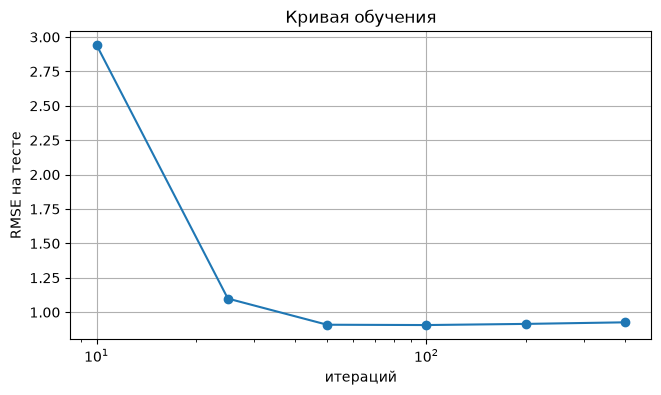

In [9]:
# --- RMSE по числу итераций ---
curve = []
for n in (10, 25, 50, 100, 200, 400):
    m = GradientBoosting(task="regression", n_estimators=n, learning_rate=0.1, max_depth=3,
                         min_samples_leaf=10).fit(Xr_tr, yr_tr)
    curve.append(metrics.rmse(yr_te, m.predict(Xr_te)))
plt.plot((10, 25, 50, 100, 200, 400), curve, "o-")
plt.xscale("log"); plt.xlabel("итераций"); plt.ylabel("RMSE на тесте"); plt.title("Кривая обучения"); plt.show()

## Выводы

1. Свой бустинг по качеству на уровне sklearn, а в регрессии его обходит
   (RMSE 0.915 против 1.019) — сказывается большее число итераций и постоянный
   шаг Ньютона; код при этом полностью прозрачен.
2. Классический компромисс шага и числа итераций подтверждается: lr = 0.1, n = 100
   дают лучший RMSE (0.9066); шаг 0.3 деградирует (0.955–0.982) при любом n.
3. Глубина 2–3 — оптимум: на 5 теряется и accuracy (0.523), и RMSE (0.923).
4. Стохастический бустинг даёт символический прирост: subsample 0.8 → RMSE 0.9139
   против 0.9149 при полной выборке.
5. На классификации бустинг — лучший результат среди всех лабораторных
   (accuracy 0.543, AUC 0.537), но потолок ≈ 0.54 не пробит.
6. Бустинг требует согласовывать lr, n_estimators и глубину — цена за нелинейность;
   при почти линейном сигнале (доходности облигаций) линейная модель даёт
   то же качество проще.